# Final Model Comparison & Summary

Goal: predict which customers are most likely to make a repeat purchase to help with retention marketing

| Section | What it covers | Source notebooks |
|---|---|---|
| **1. What makes a high-value customer** | Behavior patterns of high-value customer | `1-logistic_regression`, `2-randomforest_decisiontree` |
| **2. Repeat-purchase prediction** | Predict repeat purchaser based on models of notebook 1 & 2 | `1-logistic_regression`, `2-randomforest_decisiontree` |
| **3. Gradient boosting** | Cleaned-up version of notebook 3's second half: same tuning for every model, final model chosen by CV, campaign scores for the quarter after the data ends. | `3-gradient_boost` |
| **4. Next steps for notebook 4** | How to combine the repeat-purchase scores with the category propensity model. | `4-category_propensity_model` |

# 0. Setup

In [1]:
%pip install -q openpyxl shap

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap

from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, f1_score,
                             precision_recall_curve, precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42
HOLDOUT_DAYS = 90

In [3]:
# use the local copy if the repo is cloned, otherwise read from GitHub (e.g. on Colab)
LOCAL_PATH = '../data/Online Retail.xlsx'
GITHUB_URL = 'https://raw.githubusercontent.com/Break-Through-Tech/witOmni-1A-ai-powered-customer-intelligence-for-smarter-marketing/main/data/Online%20Retail.xlsx'

df = pd.read_excel(LOCAL_PATH if os.path.exists(LOCAL_PATH) else GITHUB_URL)
df.shape

(541909, 8)

## Data cleaning

Same steps as notebooks 1–3.

In [4]:
df = df.drop_duplicates()

# removing all the rows w/ missing customerID
df = df.dropna(subset=["CustomerID"])

# removing cancellation/returned items
df = df[~df["InvoiceNo"].astype(str).str.upper().str.startswith("C")]

# removing invalid transactions (invalid prices or quantities)
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]

df["CustomerID"] = df["CustomerID"].astype(int)
df["TotalPrice"] = df["Quantity"] * df["UnitPrice"]

print("Shape: ", df.shape)
print("Unique customers:", df["CustomerID"].nunique())

Shape:  (392692, 9)
Unique customers: 4338


# 1. What Makes a High-Value Customer (Notebooks 1 & 2)

Notebooks 1 and 2 labelled customers `High_Value_Loyal` when all three were true:

- Monetary (total spent) ≥ median
- Frequency (number of invoices) ≥ median
- Recency (days since last purchase) ≤ median

About 33% of customers get the label. Because Monetary, Frequency and Recency define the label, they were left out of the features. Features used:

| Feature | Meaning |
|---|---|
| `total_quantity` | Total items bought |
| `unique_products` | Number of distinct products bought |
| `product_diversity_ratio` | `unique_products / total_quantity`. Low = many units of each product (bulk buying) |
| `repeat_purchase_rate` | Share of a customer's products bought on more than one occasion |
| `average_order_value` | £ per invoice |

The cells below rebuild that table and refit the three models with the settings notebooks 1 and 2 tuned. This reproduces their results here so they can be compared with Sections 2 and 3.

## 1.1 Rebuild the notebook 1 customer table

In [5]:
# one row per customer over the full year (notebooks 1 and 2)
snapshot_date = df["InvoiceDate"].max()
rfm = df.groupby("CustomerID").agg(
    last_purchase=("InvoiceDate", "max"),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalPrice", "sum"),
    total_quantity=("Quantity", "sum"),
    unique_products=("StockCode", "nunique"),
)
rfm["Recency"] = (snapshot_date - rfm["last_purchase"]).dt.days
rfm["average_order_value"] = rfm["Monetary"] / rfm["Frequency"]
rfm["product_diversity_ratio"] = rfm["unique_products"] / rfm["total_quantity"]
rfm["repeat_purchase_rate"] = (df.groupby(["CustomerID", "StockCode"]).size() > 1).groupby("CustomerID").mean()

rfm["High_Value_Loyal"] = (
    (rfm["Monetary"] >= rfm["Monetary"].median()) &
    (rfm["Frequency"] >= rfm["Frequency"].median()) &
    (rfm["Recency"] <= rfm["Recency"].median())
).astype(int)

high_value_features = ["total_quantity", "unique_products", "product_diversity_ratio",
                       "repeat_purchase_rate", "average_order_value"]
rfm["High_Value_Loyal"].value_counts()

High_Value_Loyal
0    2912
1    1426
Name: count, dtype: int64

## 1.2 Refit the notebook 1 and 2 models

Same 80/20 stratified split as notebooks 1 and 2, with the best settings their grid searches found:

- Logistic regression: `C=100` (notebook 1)
- Decision tree: `criterion="entropy", max_depth=5, min_samples_leaf=10` (notebook 2)
- Random forest: `n_estimators=100, max_depth=4, min_samples_leaf=10` (notebook 2)

In [6]:
X_hv_train, X_hv_test, y_hv_train, y_hv_test = train_test_split(
    rfm[high_value_features], rfm["High_Value_Loyal"], test_size=0.2, stratify=rfm["High_Value_Loyal"], random_state=RANDOM_STATE
)

high_value_models = {
    "Logistic Regression": Pipeline([("scaler", StandardScaler()), ("model", LogisticRegression(C=100, random_state=RANDOM_STATE))]),
    "Decision Tree": DecisionTreeClassifier(criterion="entropy", max_depth=5, min_samples_leaf=10, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=4, min_samples_leaf=10, random_state=RANDOM_STATE),
}
for model in high_value_models.values():
    model.fit(X_hv_train, y_hv_train)

pd.DataFrame({name: {"Test ROC-AUC": roc_auc_score(y_hv_test, model.predict_proba(X_hv_test)[:, 1])}
              for name, model in high_value_models.items()}).T.round(3)

,Test ROC-AUC
Logistic Regression,0.918
Decision Tree,0.912
Random Forest,0.924


## 1.3 Feature importance: which behaviours describe high-value customers?

- **Logistic regression coefficients** (standardised features): sign = direction, size = strength.
- **Tree feature importances**: share of the splits' impurity reduction, always positive.

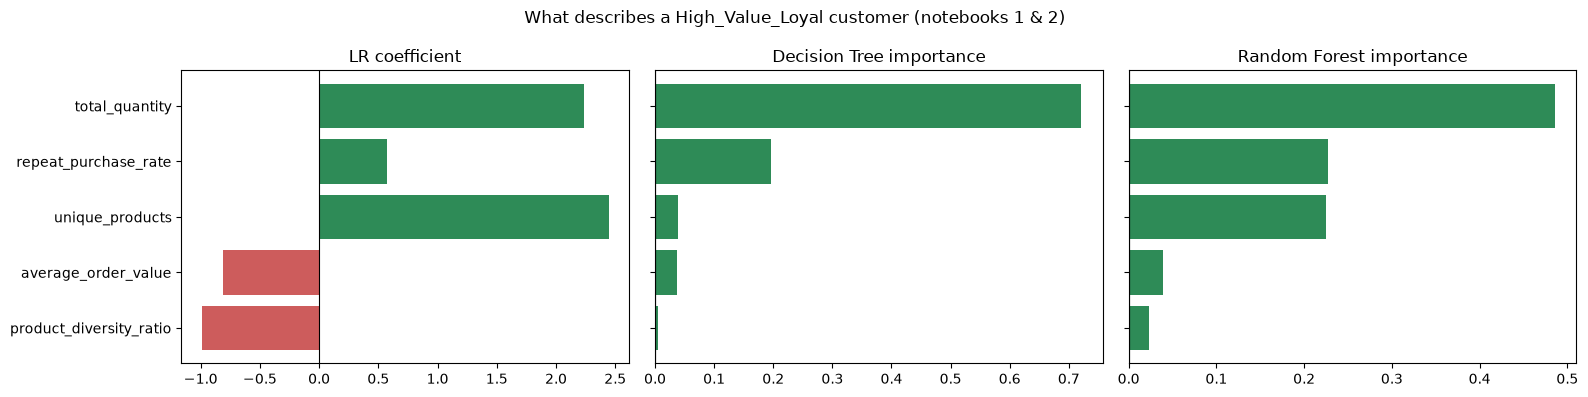

,LR coefficient,Decision Tree importance,Random Forest importance
total_quantity,2.240,0.721,0.486
repeat_purchase_rate,0.573,0.197,0.228
unique_products,2.445,0.039,0.225
average_order_value,-0.815,0.037,0.039
product_diversity_ratio,-0.991,0.006,0.023


In [7]:
high_value_importance = pd.DataFrame({
    "LR coefficient": high_value_models["Logistic Regression"].named_steps["model"].coef_[0],
    "Decision Tree importance": high_value_models["Decision Tree"].feature_importances_,
    "Random Forest importance": high_value_models["Random Forest"].feature_importances_,
}, index=high_value_features).sort_values("Random Forest importance", ascending=False)

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, column in zip(axes, high_value_importance.columns):
    values = high_value_importance[column]
    ax.barh(values.index, values, color=["seagreen" if v > 0 else "indianred" for v in values])
    ax.axvline(0, color="k", linewidth=.8); ax.set_title(column)
axes[0].invert_yaxis()
plt.suptitle("What describes a High_Value_Loyal customer (notebooks 1 & 2)")
plt.tight_layout(); plt.show()
high_value_importance.round(3)

**Summary** High-value & loyal customers characteristics:

1. **Buy in volume** (`total_quantity`). The top tree feature (about 0.72 of the decision tree's importance, 0.49 of the random forest's) and the second-largest positive coefficient.
2. **Buy a wide range of products** (`unique_products`). The largest logistic regression coefficient and the random forest's third feature, just behind repeat purchase rate.
3. **Come back for the same products** (`repeat_purchase_rate`). Positive in every model and the second feature in both trees, i.e. habitual restocking.
4. **Buy several units of each product** (negative coefficient on `product_diversity_ratio`). Given the same range of products, the high-value group buys more of each, which looks like wholesale or reseller behavior.
5. **Place many moderate orders rather than a few big ones** (negative coefficient on `average_order_value` once volume is controlled for). That fits the label, which requires above-median Frequency.

**Marketing summary:** The best customers are those who buy a wide range of products in large quantities and have consistent purchasing habits. Compared to one-time discounts, offering extended product range deals (such as bundled sales, "whole set packages") and restocking reminders is more suitable for them.

## 1.4 Note about notebook 1 2 result

The result is descriptive about valuebale customers' behaviors rather than predictive. Notebooks 1 and 2 reached ~0.92 ROC-AUC which answers a different question from the challenge:

1. **The label is a formula, not a prediction.** Applying the median rule directly gives 100% accuracy, so a model adds nothing for this label.
2. **The features are near-copies of the formula's inputs.** More items almost always means more £ spent, so `total_quantity` on its own already ranks customers almost as well as the models (cell below).
3. **Features and label come from the same year.** Nothing is being predicted about the future.

So Section 1 tells us **what high-value customers look like**. It does not tell us **who will buy again**. Section 2 asks that directly.

In [8]:
print("Spearman correlation of total_quantity and Monetary:", round(rfm["total_quantity"].corr(rfm["Monetary"], method="spearman"), 3))
print("ROC-AUC of total_quantity alone (no model):        ", round(roc_auc_score(y_hv_test, X_hv_test["total_quantity"]), 3))

Spearman correlation of total_quantity and Monetary: 0.928
ROC-AUC of total_quantity alone (no model):         0.9


# 2. From High-Value Label to Repeat-Purchase Prediction (Notebooks 1 & 2, rerun)

The challenge asks which customers will **become** repeat purchasers, so this section changes the target:

1. Pick a cutoff date 90 days before the end of the data.
2. Build features **only from transactions before the cutoff**.
3. Label a customer `1` if they purchase again in the 90 days **after** the cutoff.

The model never sees the period it is predicting, so the scores reflect what it can do on new data.

Then the notebook 1 and 2 models (logistic regression, decision tree, random forest) are retrained on this target. Compared with notebooks 1 and 2, three things change:

- **Target:** `High_Value_Loyal` → `repeat_purchase_90d`.
- **Features:** recency, tenure, order count, spend and order gap are allowed now (they no longer define the label), next to notebook 1's product diversity features.
- **Tuning:** every model uses the same 5 folds and is tuned for ROC-AUC (notebooks 1 and 2 tuned for recall), with `class_weight="balanced"`.

## 2.1 Customer features before the cutoff

`build_features` computes one row per customer using only the transactions before `as_of`. We call it twice:

- at the **cutoff date** to build the training table (the label comes from the 90 days after),
- at the **end of the data** to score customers for the next real campaign.

Features come from notebook 3 (recency, tenure, order count, spend, order gap) plus the product diversity features from notebook 1.

In [9]:
def build_features(transactions, as_of):
    history = transactions[transactions["InvoiceDate"] < as_of]

    features = history.groupby("CustomerID").agg(
        last_purchase=("InvoiceDate", "max"),
        first_purchase=("InvoiceDate", "min"),
        invoice_count=("InvoiceNo", "nunique"),
        total_spend=("TotalPrice", "sum"),
        total_items=("Quantity", "sum"),
        unique_products=("StockCode", "nunique"),
    )
    features["recency_days"] = (as_of - features["last_purchase"]).dt.days
    features["customer_age_days"] = (as_of - features["first_purchase"]).dt.days
    features["avg_order_value"] = features["total_spend"] / features["invoice_count"]

    # average days between orders (0 for single-order customers, invoice_count tells them apart)
    order_dates = history[["CustomerID", "InvoiceNo", "InvoiceDate"]].drop_duplicates("InvoiceNo").sort_values("InvoiceDate")
    order_dates["order_gap"] = order_dates.groupby("CustomerID")["InvoiceDate"].diff().dt.days
    features["mean_order_gap_days"] = order_dates.groupby("CustomerID")["order_gap"].mean().fillna(0)

    # product diversity features from notebook 1
    features["product_diversity_ratio"] = features["unique_products"] / features["total_items"]
    product_counts = history.groupby(["CustomerID", "StockCode"]).size()
    features["repeat_purchase_rate"] = (product_counts > 1).groupby("CustomerID").mean()

    return features.drop(columns=["last_purchase", "first_purchase"])


feature_columns = [
    "recency_days", "customer_age_days", "invoice_count", "total_spend", "total_items",
    "unique_products", "avg_order_value", "mean_order_gap_days",
    "product_diversity_ratio", "repeat_purchase_rate",
]

## 2.2 Repeat-purchase label

In [10]:
cutoff_date = df["InvoiceDate"].max() - pd.Timedelta(days=HOLDOUT_DAYS)
future_customers = set(df.loc[df["InvoiceDate"] >= cutoff_date, "CustomerID"])

customers = build_features(df, cutoff_date)
customers["repeat_purchase_90d"] = customers.index.isin(future_customers).astype(int)

print(f"Cutoff: {cutoff_date.date()} | Customers with history before cutoff: {len(customers):,}")
customers["repeat_purchase_90d"].value_counts(normalize=True).rename("share").to_frame()

Cutoff: 2011-09-10 | Customers with history before cutoff: 3,370


,share
repeat_purchase_90d,
1,0.57003
0,0.42997


In [11]:
customers[feature_columns].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
recency_days,3370.0,94.49,79.98,0.0,25.00,74.00,151.00,283.00
customer_age_days,3370.0,182.40,80.47,0.0,123.00,193.00,264.00,283.00
invoice_count,3370.0,3.53,5.79,1.0,1.00,2.00,4.00,132.00
total_spend,3370.0,1615.13,6148.01,2.9,264.64,563.21,1388.94,178302.62
total_items,3370.0,949.74,3827.36,1.0,131.00,313.00,780.00,127744.00
unique_products,3370.0,49.93,67.55,1.0,14.00,29.00,63.00,1230.00
avg_order_value,3370.0,397.32,1422.63,2.9,168.30,283.08,412.41,77183.60
mean_order_gap_days,3370.0,35.06,45.94,0.0,0.00,20.00,53.46,270.00
product_diversity_ratio,3370.0,0.13,0.13,0.0,0.06,0.09,0.15,1.00
repeat_purchase_rate,3370.0,0.14,0.19,0.0,0.00,0.05,0.21,1.00


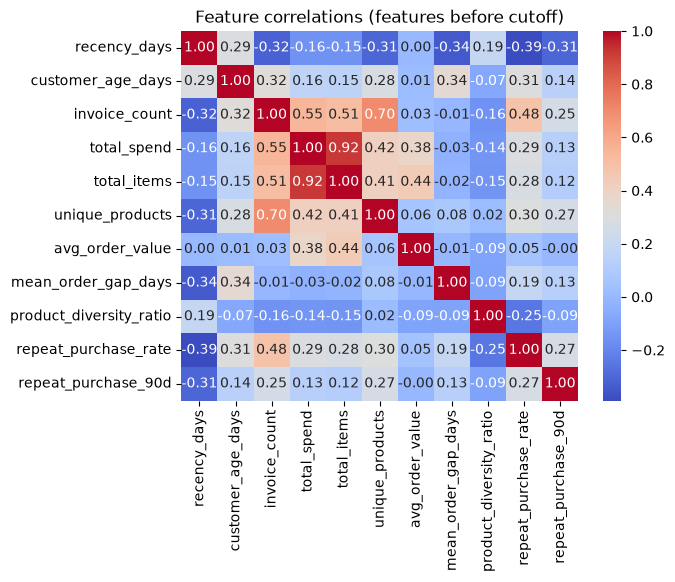

In [12]:
sns.heatmap(customers[feature_columns + ["repeat_purchase_90d"]].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Feature correlations (features before cutoff)")
plt.show()

## 2.3 Train / test split

A stratified 80/20 split of customers with `random_state=42`, the same split notebook 3 used. The test set is not touched until the final evaluation. All tuning happens with 5-fold cross-validation on the training set.

In [13]:
X = customers[feature_columns]
y = customers["repeat_purchase_90d"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (2696, 10)
Testing set: (674, 10)


## 2.4 Model training

Each model is tuned with the same cross-validation folds. We tune for **ROC-AUC** because marketing will use the model to *rank* customers, and the decision threshold is chosen later based on campaign capacity. Grids are taken from notebooks 1–3.

`tune` runs the grid search, keeps the best model, and records its cross-validated metrics on the training set (mean ± std across folds). It is reused for gradient boosting in Section 3.

In [14]:
models, cv_results = {}, {}
cv_metrics = ["accuracy", "precision", "recall", "f1", "roc_auc"]

def tune(name, pipeline, grid):
    search = GridSearchCV(pipeline, grid, scoring="roc_auc", cv=cv, n_jobs=-1)
    search.fit(X_train, y_train)
    models[name] = search.best_estimator_
    print(f"{name}: {search.best_params_}")

    scores = cross_validate(search.best_estimator_, X_train, y_train, cv=cv, scoring=cv_metrics)
    cv_results[name] = {m: f"{scores[f'test_{m}'].mean():.3f} ± {scores[f'test_{m}'].std():.3f}" for m in cv_metrics}
    return pd.DataFrame(cv_results[name], index=[name])

### Logistic regression (notebook 1)

In [15]:
tune("Logistic Regression",
     Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler()),
               ("model", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE))]),
     {"model__C": [0.01, 0.1, 1, 10, 100]})

Logistic Regression: {'model__C': 1}


,accuracy,precision,recall,f1,roc_auc
Logistic Regression,0.668 ± 0.015,0.785 ± 0.010,0.574 ± 0.025,0.663 ± 0.020,0.746 ± 0.018


### Decision tree (notebook 2)

In [16]:
tune("Decision Tree",
     Pipeline([("imputer", SimpleImputer(strategy="median")),
               ("model", DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE))]),
     {"model__max_depth": [3, 5, 8, 10], "model__min_samples_leaf": [5, 10, 20, 50],
      "model__criterion": ["gini", "entropy"]})

Decision Tree: {'model__criterion': 'entropy', 'model__max_depth': 3, 'model__min_samples_leaf': 20}


,accuracy,precision,recall,f1,roc_auc
Decision Tree,0.660 ± 0.017,0.794 ± 0.027,0.548 ± 0.036,0.647 ± 0.023,0.729 ± 0.019


### Random forest (notebook 2)

In [17]:
tune("Random Forest",
     Pipeline([("imputer", SimpleImputer(strategy="median")),
               ("model", RandomForestClassifier(class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE))]),
     {"model__n_estimators": [100, 300], "model__max_depth": [4, 6, 8, 10], "model__min_samples_leaf": [5, 10, 20]})

Random Forest: {'model__max_depth': 4, 'model__min_samples_leaf': 10, 'model__n_estimators': 300}


,accuracy,precision,recall,f1,roc_auc
Random Forest,0.671 ± 0.016,0.765 ± 0.016,0.612 ± 0.024,0.680 ± 0.018,0.749 ± 0.015


## 2.5 Results on the new target

Two baselines show how much the models add:

- **Random guess**: a `DummyClassifier` that predicts the class proportions.
- **Recency only**: rank customers by how recently they last bought. This is the simple rule a marketer would use without a model.

In [18]:
def evaluate(name, prob, threshold=0.5):
    pred = (prob >= threshold).astype(int)
    return {"Model": name,
            "Accuracy": accuracy_score(y_test, pred),
            "Precision": precision_score(y_test, pred, zero_division=0),
            "Recall": recall_score(y_test, pred, zero_division=0),
            "F1": f1_score(y_test, pred, zero_division=0),
            "ROC-AUC": roc_auc_score(y_test, prob)}

def results_table():
    probabilities = {name: model.predict_proba(X_test)[:, 1] for name, model in models.items()}
    dummy = DummyClassifier(strategy="stratified", random_state=RANDOM_STATE).fit(X_train, y_train)
    rows = [evaluate(name, prob) for name, prob in probabilities.items()]
    rows.append(evaluate("Baseline: random guess", dummy.predict_proba(X_test)[:, 1]))
    rows.append({"Model": "Baseline: recency only", "ROC-AUC": roc_auc_score(y_test, -X_test["recency_days"])})
    return probabilities, pd.DataFrame(rows).set_index("Model").sort_values("ROC-AUC", ascending=False)

print("Cross-validated on the training set:")
display(pd.DataFrame.from_dict(cv_results, orient="index"))
print("Test set:")
probabilities, results_df = results_table()
results_df.round(3)

Cross-validated on the training set:


,accuracy,precision,recall,f1,roc_auc
Logistic Regression,0.668 ± 0.015,0.785 ± 0.010,0.574 ± 0.025,0.663 ± 0.020,0.746 ± 0.018
Decision Tree,0.660 ± 0.017,0.794 ± 0.027,0.548 ± 0.036,0.647 ± 0.023,0.729 ± 0.019
Random Forest,0.671 ± 0.016,0.765 ± 0.016,0.612 ± 0.024,0.680 ± 0.018,0.749 ± 0.015


Test set:


,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Random Forest,0.666,0.771,0.589,0.668,0.741
Logistic Regression,0.650,0.776,0.542,0.638,0.729
Decision Tree,0.639,0.783,0.508,0.616,0.718
Baseline: recency only,NaN,NaN,NaN,NaN,0.679
Baseline: random guess,0.501,0.562,0.565,0.564,0.491


## 2.6 Which behaviours predict a repeat purchase?

Logistic regression coefficients on the new target (features are standardised, so magnitudes are comparable). Compare with Section 1.3.

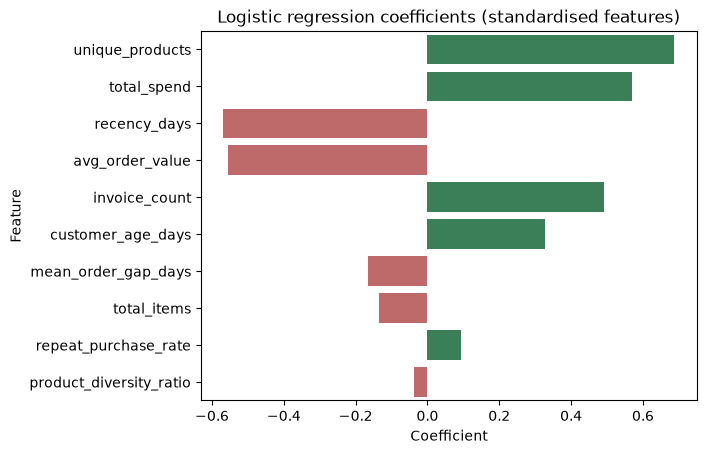

,Feature,Coefficient
5,unique_products,0.687
3,total_spend,0.570
0,recency_days,-0.568
6,avg_order_value,-0.554
2,invoice_count,0.492
1,customer_age_days,0.327
7,mean_order_gap_days,-0.166
4,total_items,-0.136
9,repeat_purchase_rate,0.095
8,product_diversity_ratio,-0.036


In [19]:
lr = models["Logistic Regression"].named_steps["model"]
coefficients = pd.DataFrame({"Feature": feature_columns, "Coefficient": lr.coef_[0]})
coefficients = coefficients.reindex(coefficients["Coefficient"].abs().sort_values(ascending=False).index)

sns.barplot(data=coefficients, x="Coefficient", y="Feature",
            hue=coefficients["Coefficient"] > 0, palette={True: "seagreen", False: "indianred"}, legend=False)
plt.title("Logistic regression coefficients (standardised features)")
plt.show()
coefficients.round(3)

**How the picture changes from Section 1:**

- **Recency and order count become key signals.** Customers who bought recently and have placed more orders are the ones who come back (coefficients −0.57 and +0.49 here; the top two features of the final model in Section 3.4). Notebooks 1 and 2 could not show this because those columns defined their label.
- **Product range still helps.** `unique_products` has the largest positive coefficient here too, so breadth of buying is the one behaviour that both describes today's high-value customers *and* predicts a return.
- **Volume no longer adds anything.** `total_items` was the top feature for `High_Value_Loyal`, but once spend and order count are in the model it has a small negative coefficient. Volume described the label rather than future behaviour.
- **Repeat purchase rate and diversity ratio fade** to near zero.
- **ROC-AUC drops from ~0.92 to ~0.72–0.75.** This is the honest number: it measures predicting next quarter, not copying a formula.

So notebooks 1 and 2 remain useful as **descriptive** segmentation (who the best customers are today). The temporal models are the ones to use for **targeting** (who will buy next).

# 3. Gradient Boosting, Fixed (Notebook 3)

Notebook 3's second half introduced the temporal target used in Section 2 and added a gradient boosting model, threshold table and marketing segments. This section keeps its cutoff, target, features, gradient boosting grid, threshold table and segments, with these fixes:

| Issue in notebook 3 | Fix here |
|---|---|
| Only gradient boosting was tuned; the other models used defaults. | Every model goes through the same `GridSearchCV` (same folds, same scoring) via `tune`. |
| Final model picked by test-set score. | Final model picked by cross-validated ROC-AUC; the test set is only used to report. |
| Campaign scores predicted the 90 days already in the data. | Model is refit on all labelled customers and scores features as of the **end** of the data, i.e. the next quarter. |
| Some cells depended on variables from notebook 4. | Runs top to bottom on its own. |

**Additions:** a recency-only baseline, permutation importance and SHAP explanations, a calibration check, a segment profile table, and a CSV export of the scores.

## 3.1 Gradient boosting (notebook 3)

Same grid as notebook 3, tuned on the same folds as the Section 2 models. Gradient boosting has no `class_weight` option; the classes are close to balanced (57% / 43%), so this is not a problem.

In [20]:
tune("Gradient Boosting",
     Pipeline([("imputer", SimpleImputer(strategy="median")),
               ("model", GradientBoostingClassifier(random_state=RANDOM_STATE))]),
     {"model__n_estimators": [100, 200], "model__learning_rate": [0.03, 0.05, 0.1],
      "model__max_depth": [2, 3], "model__min_samples_leaf": [5, 10], "model__subsample": [0.8, 1.0]})

Gradient Boosting: {'model__learning_rate': 0.03, 'model__max_depth': 2, 'model__min_samples_leaf': 5, 'model__n_estimators': 100, 'model__subsample': 0.8}


,accuracy,precision,recall,f1,roc_auc
Gradient Boosting,0.684 ± 0.012,0.731 ± 0.009,0.706 ± 0.027,0.718 ± 0.015,0.751 ± 0.016


## 3.2 Compare all four models

In [21]:
cv_summary = pd.DataFrame.from_dict(cv_results, orient="index")
cv_summary

,accuracy,precision,recall,f1,roc_auc
Logistic Regression,0.668 ± 0.015,0.785 ± 0.010,0.574 ± 0.025,0.663 ± 0.020,0.746 ± 0.018
Decision Tree,0.660 ± 0.017,0.794 ± 0.027,0.548 ± 0.036,0.647 ± 0.023,0.729 ± 0.019
Random Forest,0.671 ± 0.016,0.765 ± 0.016,0.612 ± 0.024,0.680 ± 0.018,0.749 ± 0.015
Gradient Boosting,0.684 ± 0.012,0.731 ± 0.009,0.706 ± 0.027,0.718 ± 0.015,0.751 ± 0.016


In [22]:
probabilities, results_df = results_table()
results_df.round(3)

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Gradient Boosting,0.688,0.734,0.711,0.722,0.746
Random Forest,0.666,0.771,0.589,0.668,0.741
Logistic Regression,0.650,0.776,0.542,0.638,0.729
Decision Tree,0.639,0.783,0.508,0.616,0.718
Baseline: recency only,NaN,NaN,NaN,NaN,0.679
Baseline: random guess,0.501,0.562,0.565,0.564,0.491


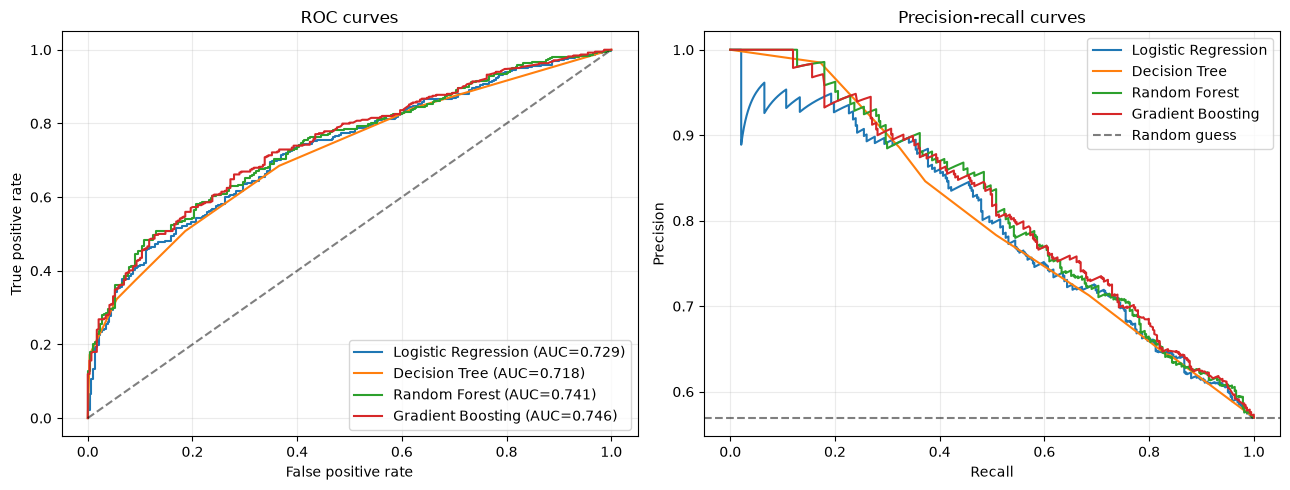

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, prob in probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    precision, recall, _ = precision_recall_curve(y_test, prob)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, prob):.3f})")
    axes[1].plot(recall, precision, label=name)
axes[0].plot([0, 1], [0, 1], "k--", alpha=.5)
axes[1].axhline(y_test.mean(), color="k", linestyle="--", alpha=.5, label="Random guess")
axes[0].set(title="ROC curves", xlabel="False positive rate", ylabel="True positive rate")
axes[1].set(title="Precision-recall curves", xlabel="Recall", ylabel="Precision")
for ax in axes: ax.legend(); ax.grid(alpha=.25)
plt.tight_layout(); plt.show()

## 3.3 Final model selection

We select the final model by **cross-validated ROC-AUC on the training set**, not by test score, so the test set stays an unbiased estimate. Logistic regression is kept alongside it as the interpretable baseline: its coefficient signs tell marketers which direction each behaviour pushes.

Final model: Gradient Boosting
                    precision    recall  f1-score   support

No repeat purchase       0.63      0.66      0.65       290
   Repeat purchase       0.73      0.71      0.72       384

          accuracy                           0.69       674
         macro avg       0.68      0.68      0.68       674
      weighted avg       0.69      0.69      0.69       674



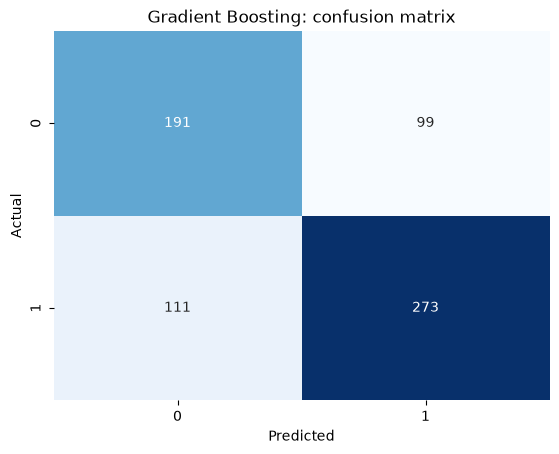

In [24]:
cv_auc = cv_summary["roc_auc"].str.split(" ± ").str[0].astype(float)
best_name = cv_auc.idxmax()
best_model = models[best_name]
best_prob = probabilities[best_name]
best_pred = (best_prob >= 0.5).astype(int)

print("Final model:", best_name)
print(classification_report(y_test, best_pred, target_names=["No repeat purchase", "Repeat purchase"]))
sns.heatmap(confusion_matrix(y_test, best_pred), annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title(f"{best_name}: confusion matrix"); plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.show()

## 3.4 What drives the final model's predictions?

1. **Permutation importance** on the test set: how much ROC-AUC drops when a feature is shuffled.
2. **SHAP values**: how each feature pushes individual customers' predictions up or down.

The logistic regression coefficients in Section 2.6 give the direction of each effect.

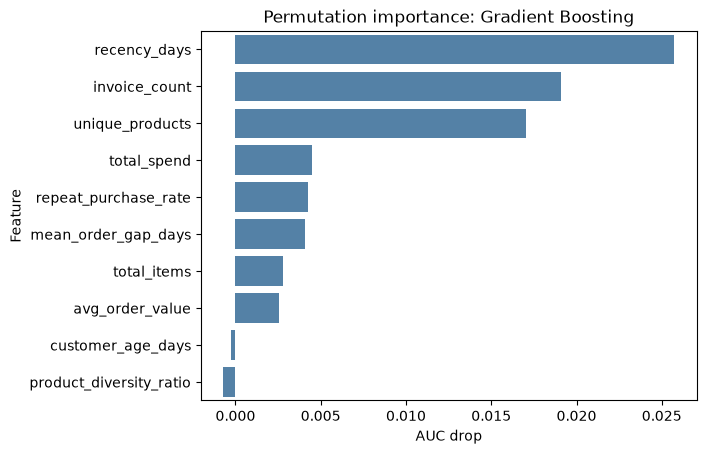

,Feature,AUC drop,Std
0,recency_days,0.0257,0.0072
2,invoice_count,0.0191,0.0080
5,unique_products,0.0170,0.0057
3,total_spend,0.0045,0.0031
9,repeat_purchase_rate,0.0042,0.0035
7,mean_order_gap_days,0.0041,0.0042
4,total_items,0.0028,0.0016
6,avg_order_value,0.0026,0.0017
1,customer_age_days,-0.0003,0.0012
8,product_diversity_ratio,-0.0007,0.0007


In [25]:
perm = permutation_importance(best_model, X_test, y_test, scoring="roc_auc", n_repeats=20, random_state=RANDOM_STATE)
perm_importance = pd.DataFrame({"Feature": feature_columns, "AUC drop": perm.importances_mean, "Std": perm.importances_std})
perm_importance = perm_importance.sort_values("AUC drop", ascending=False)

sns.barplot(data=perm_importance, x="AUC drop", y="Feature", color="steelblue")
plt.title(f"Permutation importance: {best_name}")
plt.show()
perm_importance.round(4)

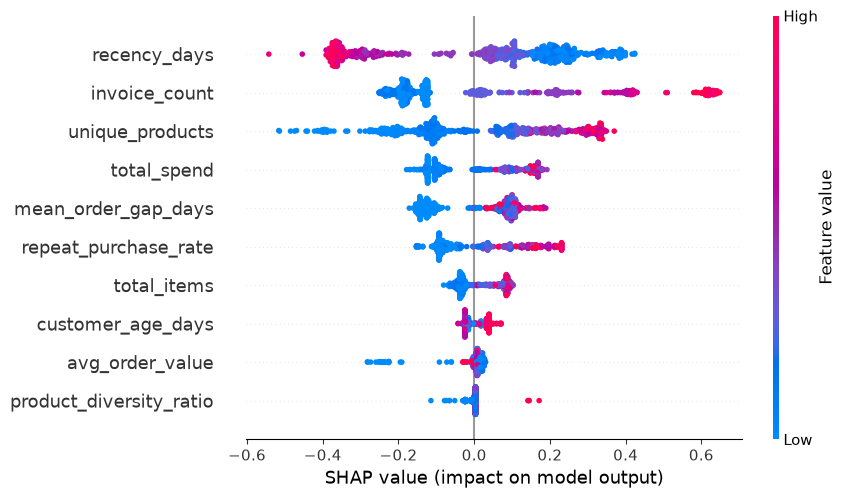

In [26]:
# SHAP works on the fitted estimator, so pass the data through the pipeline's preprocessing first
preprocess = best_model[:-1]
X_test_transformed = pd.DataFrame(preprocess.transform(X_test), columns=feature_columns, index=X_test.index)

explainer = shap.Explainer(best_model.named_steps["model"], preprocess.transform(X_train), feature_names=feature_columns)
shap_values = explainer(X_test_transformed)
if shap_values.values.ndim == 3:  # some tree models return one set of values per class; keep "repeat purchase"
    shap_values = shap_values[..., 1]
shap.plots.beeswarm(shap_values, max_display=len(feature_columns))

## 3.5 Choosing a threshold for campaigns

The 0.5 cut-off is arbitrary. In practice the threshold depends on how many customers the campaign can reach and what a wasted contact costs compared with a missed repeat buyer. The table shows the trade-off on the test set.

In [27]:
threshold_rows = []
for threshold in np.arange(.20, .81, .05):
    pred = (best_prob >= threshold).astype(int)
    threshold_rows.append({"Threshold": round(float(threshold), 2),
                           "Customers targeted": int(pred.sum()),
                           "Share targeted": pred.mean(),
                           "Precision": precision_score(y_test, pred, zero_division=0),
                           "Recall": recall_score(y_test, pred, zero_division=0),
                           "F1": f1_score(y_test, pred, zero_division=0)})
pd.DataFrame(threshold_rows).round(3)

,Threshold,Customers targeted,Share targeted,Precision,Recall,F1
0,0.20,674,1.000,0.570,1.000,0.726
1,0.25,672,0.997,0.571,1.000,0.727
2,0.30,659,0.978,0.578,0.992,0.731
3,0.35,554,0.822,0.625,0.901,0.738
4,0.40,520,0.772,0.640,0.867,0.737
5,0.45,433,0.642,0.691,0.779,0.732
6,0.50,372,0.552,0.734,0.711,0.722
7,0.55,310,0.460,0.761,0.615,0.680
8,0.60,264,0.392,0.795,0.547,0.648
9,0.65,225,0.334,0.836,0.490,0.617


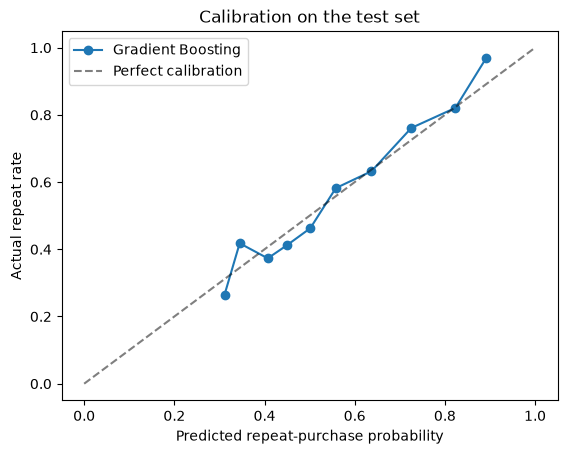

In [28]:
# are the predicted probabilities trustworthy as probabilities? points near the diagonal = well calibrated
actual, predicted = calibration_curve(y_test, best_prob, n_bins=10, strategy="quantile")
plt.plot(predicted, actual, marker="o", label=best_name)
plt.plot([0, 1], [0, 1], "k--", alpha=.5, label="Perfect calibration")
plt.xlabel("Predicted repeat-purchase probability"); plt.ylabel("Actual repeat rate")
plt.title("Calibration on the test set"); plt.legend(); plt.show()

## 3.6 Scoring customers for the next campaign

For a real campaign we want to predict the 90 days **after the data ends**, not the period we trained on. So we:

1. Refit the final model on all labelled customers (train + test).
2. Rebuild features as of the last date in the data, which includes every customer up to today.
3. Score every customer and assign a marketing segment (segment rules from notebook 3).

In [29]:
campaign_model = clone(best_model).fit(X, y)

scoring_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)
latest = build_features(df, scoring_date)
latest["repeat_purchase_probability"] = campaign_model.predict_proba(latest[feature_columns])[:, 1]

def segment(row):
    if row["repeat_purchase_probability"] >= .70 and row["recency_days"] <= 45: return "High-probability active"
    if row["repeat_purchase_probability"] >= .50: return "Promising reactivation"
    if row["recency_days"] > 180: return "At-risk / lapsed"
    return "Nurture"

actions = {
    "High-probability active": "Recommend complementary products or loyalty benefits; avoid unnecessary discounts.",
    "Promising reactivation": "Send personalised reminders and a time-limited incentive.",
    "At-risk / lapsed": "Test win-back messaging, cap spend, and measure incremental lift.",
    "Nurture": "Use low-cost content and product discovery messages.",
}
latest["marketing_segment"] = latest.apply(segment, axis=1)
latest["recommended_action"] = latest["marketing_segment"].map(actions)

print(f"Scored {len(latest):,} customers as of {scoring_date.date()}")
latest.sort_values("repeat_purchase_probability", ascending=False)[
    ["repeat_purchase_probability", "marketing_segment", "recency_days", "invoice_count", "total_spend"]
].head(10).round(3)

Scored 4,338 customers as of 2011-12-10


,repeat_purchase_probability,marketing_segment,recency_days,invoice_count,total_spend
CustomerID,,,,,
16779,0.907,High-probability active,2,22,10611.72
16426,0.907,High-probability active,2,10,1863.76
16700,0.907,High-probability active,9,13,5076.55
14367,0.907,High-probability active,8,16,9227.82
16187,0.907,High-probability active,32,15,6911.44
15249,0.907,High-probability active,32,13,6688.46
12678,0.907,High-probability active,42,12,17628.46
16713,0.907,High-probability active,19,15,6910.78
15144,0.907,High-probability active,8,17,6580.44


In [30]:
segment_order = list(actions)
segment_profile = latest.groupby("marketing_segment").agg(
    customers=("repeat_purchase_probability", "size"),
    avg_probability=("repeat_purchase_probability", "mean"),
    median_recency_days=("recency_days", "median"),
    median_orders=("invoice_count", "median"),
    median_spend=("total_spend", "median"),
    total_spend=("total_spend", "sum"),
).reindex(segment_order)
segment_profile["share_of_revenue"] = segment_profile["total_spend"] / segment_profile["total_spend"].sum()
segment_profile.round(2)

,customers,avg_probability,median_recency_days,median_orders,median_spend,total_spend,share_of_revenue
marketing_segment,,,,,,,
High-probability active,1199,0.85,13.0,7.0,2322.40,6297528.78,0.71
Promising reactivation,1480,0.63,54.5,3.0,744.19,1675428.12,0.19
At-risk / lapsed,785,0.36,267.0,1.0,271.85,447753.48,0.05
Nurture,874,0.43,72.0,1.0,259.02,466498.51,0.05


In [31]:
# save the scores so the dashboard / LLM stretch goals (and notebook 4) can use them
os.makedirs("../data/model_outputs", exist_ok=True)
latest.reset_index()[["CustomerID", "repeat_purchase_probability", "marketing_segment", "recommended_action"] + feature_columns] \
    .to_csv("../data/model_outputs/repeat_purchase_scores.csv", index=False)

## 3.7 Limitations and assumptions

- **One retailer, one year.** The data covers a single UK gift retailer (many customers are wholesalers) from Dec 2010 to Dec 2011, so results may not carry over to other businesses.
- **One time window.** The model is trained and tested on a single cutoff. The 90-day window also includes the November–December Christmas peak, which may inflate repeat rates compared with other quarters. The campaign scores above predict the quarter after the data ends (Dec–Mar), so they are likely too optimistic: use them to *rank* customers rather than as exact probabilities. Re-testing on an earlier cutoff would show how stable the model is.
- **The test set is small** (~670 customers), so differences of a few points between models are within noise. Compare the ± std in the cross-validation table.
- **Prediction is not causation.** The model predicts who will buy again, not who will buy *because of* marketing. Customers in "High-probability active" may buy anyway; use A/B tests or uplift modelling to measure what campaigns actually add.
- **Only customers with a CustomerID** are included (about 25% of rows had none), and new customers with no history cannot be scored.
- **Fairness.** Country was excluded from the features to avoid targeting decisions based on nationality. Segment actions favour low-cost outreach over excluding anyone.

# 4. Next Steps for Notebook 4 (Category Propensity)

`4-category_propensity_model` predicts **which product categories** each customer will buy next quarter (27 NLP-built categories; neural net mean AUC 0.75, recall@5 0.75). This notebook predicts **whether** they come back. Notebook 4's extension plan combines the two:

$$P(\text{buys category } c) = P(\text{returns}) \times P(c \mid \text{returns})$$

The combined score is less about accuracy (notebook 4's standalone model already learns returning) and more about a separate return score that drives the playbook:

| | Clear category preference | No clear preference |
|---|---|---|
| **Likely to return** | Targeted promo for their top category | New arrivals or general loyalty offer |
| **Unlikely to return** | Win-back using the category they love | Low-cost content only |

Its "unlikely to return" row maps to this notebook's *At-risk / lapsed* and *Nurture* segments; "likely to return" maps to *High-probability active* and *Promising reactivation*.

## 4.1 What has to line up first

Comparing the two notebooks shows three mismatches. The cell below checks them.

1. **Cutoff date.** Notebook 4 uses 75% of the date range (2011-09-07); this notebook uses the last date − 90 days (2011-09-10). Use one shared rule, e.g. `df["InvoiceDate"].max() - pd.Timedelta(days=90)` in both.
2. **Customers and test split.** Notebook 4 drops non-product rows (postage, fees) before building features, has a slightly different customer set, and uses an unstratified split. If the test customers differ, one model's training customers end up in the other's test set and the combined score looks better than it is. This notebook exports its split (cell below) so notebook 4 can reuse it.
3. **Scoring date.** Notebook 4's exported scores use features as of the cutoff, i.e. they predict Sep–Dec 2011, which is already in the data. This is the same issue fixed for notebook 3 in Section 3.6: rebuild features as of the end of the data before scoring.

In [32]:
CATEGORY_SCORES_PATH = "../data/category_data/customer_category_scores.csv"

if os.path.exists(CATEGORY_SCORES_PATH):
    category_customers = set(pd.read_csv(CATEGORY_SCORES_PATH, usecols=["CustomerID"])["CustomerID"])
    print(f"Notebook 4 scored customers:            {len(category_customers):,}")
    print(f"Labelled customers in this notebook:    {len(customers):,}")
    print(f"In both:                                {len(category_customers & set(customers.index)):,}")
    print(f"Customers to score at the data end:     {len(latest):,} "
          f"({len(set(latest.index) - category_customers):,} of them have no notebook 4 score)")
else:
    print("Notebook 4's scores are not in data/category_data/; run notebook 4 first.")

Notebook 4 scored customers:            3,349
Labelled customers in this notebook:    3,370
In both:                                3,349
Customers to score at the data end:     4,338 (989 of them have no notebook 4 score)


In [33]:
# share the cutoff and the train/test customers so notebook 4 can use the same split
split = pd.DataFrame({"CustomerID": customers.index, "repeat_purchase_90d": customers["repeat_purchase_90d"].values,
                      "split": np.where(customers.index.isin(X_test.index), "test", "train"), "cutoff_date": cutoff_date.date()})
split.to_csv("../data/model_outputs/repeat_purchase_split.csv", index=False)
split["split"].value_counts()

split
train    2696
test      674
Name: count, dtype: int64

## 4.2 Plan for notebook 4

1. **Align.** Read `data/model_outputs/repeat_purchase_split.csv`; use its `cutoff_date` and its `test` customers as notebook 4's test set (customers missing from notebook 4's table can be dropped from both evaluations).
2. **Retrain on returners.** Same neural net, trained only on customers with `repeat_purchase_90d = 1`, so its outputs mean P(category | returns).
3. **Evaluate on the shared test set.** Compare the combined score with notebook 4's standalone model (mean AUC, recall@5). A tie is fine; the value is the separate return score.
4. **Calibrate both.** Multiplying two miscalibrated probabilities stacks the error. Section 3.5 has the calibration check for this model; notebook 4's model already looks well calibrated. Note that both were tested on the Sep–Dec holiday quarter.
5. **Score as of the data end.** Rebuild notebook 4's features as of the last date in the data, multiply by `repeat_purchase_probability` from `data/model_outputs/repeat_purchase_scores.csv`, then by typical category spend for expected spend.
6. **Segment and ship.** Place each customer in the 2×2 playbook using the return score and how concentrated their category scores are; add the return probability and segment to the CSV and the Streamlit views.

# 5. Summary

**Goal:** predict which customers will make a repeat purchase in the next 90 days.

**Priority 1: precision.** A false positive is a customer we target who doesn't come back, which wastes marketing spend. We therefore favour precision over recall.

**Priority 2: cost of training and running.** Model that takes less computing resources and time is favored.

**Chosen model: Random Forest.**
- Ranking quality is on par with the best model: cross-validated ROC-AUC 0.749 vs 0.751 for gradient boosting
- Highest precision of the ensemble models at the default 0.5 threshold: 0.77 on the test set, vs 0.73 for gradient boosting.
- Clearly beats the recency-only baseline (test ROC-AUC 0.741 vs 0.679).